In [1]:
import dill
import scanpy as sc
import anndata as ad
import muon as mu
import os
import warnings
warnings.filterwarnings("ignore")
import pandas
import pyranges
# Set stderr to null to avoid strange messages from ray
import sys
_stderr = sys.stderr
null = open(os.devnull,'wb')

from pycisTopic.cistopic_class import CistopicObject
from pycisTopic.lda_models import *
from pycisTopic.clust_vis import *
from pycisTopic.diff_features import *

from scenicplus.scenicplus_class import SCENICPLUS, create_SCENICPLUS_object
from scenicplus.preprocessing.filtering import *
from scenicplus.utils import region_names_to_coordinates
from scenicplus.eregulon_enrichment import make_rankings

from scenicplus.wrappers.run_scenicplus import run_scenicplus

sys.path.append('/nfs/casm/team215mg/users/od5/scripts/')
from scenicplus_modified_dotplot import *

In [2]:
## Set up work directory
work_dir = '/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/scenicplus/tf_pilot/batch1/ipsc/'
## Tmp dir for ray (this needs to be as short as possible, as there is an overall limit of the number of characters accepted by ray - max is 107):
tmp_dir = '/lustre/scratch125/casm/teams/team215/r/'
os.makedirs(tmp_dir, exist_ok=True)

grouping_variable = 'GEX_perturbation'

In [3]:
## Restart kernel and reload preinitialised scplus object:
scplus_obj = dill.load(open((work_dir + 'scenicplus_full/scplus_obj.pkl'), 'rb'))

In [4]:
scplus_obj

SCENIC+ object with n_cells x n_genes = 246 x 16752 and n_cells x n_regions = 246 x 36627
	metadata_genes:'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
	metadata_cell:'GEX_perturbation', 'GEX_perturbation_purity', 'GEX_n_genes_by_counts', 'GEX_log1p_n_genes_by_counts', 'GEX_total_counts', 'GEX_log1p_total_counts', 'GEX_pct_counts_in_top_50_genes', 'GEX_pct_counts_in_top_100_genes', 'GEX_pct_counts_in_top_200_genes', 'GEX_pct_counts_in_top_500_genes', 'ACC_rna:perturbation', 'ACC_rna:perturbation_purity', 'ACC_rna:n_genes_by_counts', 'ACC_rna:log1p_n_genes_by_counts', 'ACC_rna:total_counts', 'ACC_rna:log1p_total_counts', 'ACC_rna:pct_counts_in_top_50_genes', 'ACC_rna:pct_counts_in_top_100_genes', 'ACC_rna:pct_counts_in_top_200_genes', 'ACC_rna:pct_counts_in_top_500_genes', 'ACC_atac:perturbation', 'ACC_atac:perturbation_purity', 'ACC_perturbation', 'ACC_perturbation_purity', 'ACC_compactness', 'ACC_size'
	menr:'CTX

In [5]:
grn_comb_high_conf = pd.read_csv((work_dir + 'eregulon_metadata_full_20runs_combined_min5recall.csv'), index_col=0)

In [6]:
grn_comb_high_conf

,Triplet,TF,Region,Gene,TF2G_sign,R2G_sign,TF2R,R2G,TF2G,n_called_triplet_full,n_called_R2G_full,n_called_TF2G_full,n_called_TF2R_full,n_called_tf_full
ARID3A#chr11:107916525-107917025#RAB39A,ARID3A#chr11:107916525-107917025#RAB39A,ARID3A,chr11:107916525-107917025,RAB39A,-,+,ARID3A#chr11:107916525-107917025,chr11:107916525-107917025#RAB39A,ARID3A#RAB39A,6,6,6,6,12
ARID3A#chr11:64356450-64356950#GPR137,ARID3A#chr11:64356450-64356950#GPR137,ARID3A,chr11:64356450-64356950,GPR137,+,+,ARID3A#chr11:64356450-64356950,chr11:64356450-64356950#GPR137,ARID3A#GPR137,7,9,7,7,12
ARID3A#chr12:2691652-2692152#ITFG2,ARID3A#chr12:2691652-2692152#ITFG2,ARID3A,chr12:2691652-2692152,ITFG2,-,+,ARID3A#chr12:2691652-2692152,chr12:2691652-2692152#ITFG2,ARID3A#ITFG2,5,9,6,5,12
ARID3A#chr12:2944628-2945128#ITFG2,ARID3A#chr12:2944628-2945128#ITFG2,ARID3A,chr12:2944628-2945128,ITFG2,-,+,ARID3A#chr12:2944628-2945128,chr12:2944628-2945128#ITFG2,ARID3A#ITFG2,6,6,6,6,12
ARID3A#chr12:57456037-57456537#INHBE,ARID3A#chr12:57456037-57456537#INHBE,ARID3A,chr12:57456037-57456537,INHBE,+,+,ARID3A#chr12:57456037-57456537,chr12:57456037-57456537#INHBE,ARID3A#INHBE,5,5,7,5,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZSCAN10#chrX:48958188-48958688#TFE3,ZSCAN10#chrX:48958188-48958688#TFE3,ZSCAN10,chrX:48958188-48958688,TFE3,+,+,ZSCAN10#chrX:48958188-48958688,chrX:48958188-48958688#TFE3,ZSCAN10#TFE3,9,11,9,10,19
ZSCAN10#chrX:49002006-49002506#TFE3,ZSCAN10#chrX:49002006-49002506#TFE3,ZSCAN10,chrX:49002006-49002506,TFE3,+,+,ZSCAN10#chrX:49002006-49002506,chrX:49002006-49002506#TFE3,ZSCAN10#TFE3,7,8,9,7,19
ZSCAN10#chrX:49073807-49074307#TFE3,ZSCAN10#chrX:49073807-49074307#TFE3,ZSCAN10,chrX:49073807-49074307,TFE3,+,+,ZSCAN10#chrX:49073807-49074307,chrX:49073807-49074307#TFE3,ZSCAN10#TFE3,7,7,9,7,19
ZSCAN10#chrX:49101053-49101553#TFE3,ZSCAN10#chrX:49101053-49101553#TFE3,ZSCAN10,chrX:49101053-49101553,TFE3,+,+,ZSCAN10#chrX:49101053-49101553,chrX:49101053-49101553#TFE3,ZSCAN10#TFE3,5,5,9,5,19


In [7]:
def add_scplus_signature_names(df):
    ## Group by TF and activating/repressing signature
    df['Signature'] = df['TF'] + '_' + df['TF2G_sign'] + '_' + df['R2G_sign']
    region_counts = {}
    gene_counts = {}
    
    ## For each signature, count number of genes and regions
    for sig in df['Signature'].unique():
        region_counts[sig] = len(df['Region'][df['Signature']==sig].unique())
        gene_counts[sig] = len(df['Gene'][df['Signature']==sig].unique())
    
    ## Collect in a data.frame
    signature_df = pd.DataFrame({
        'Signature': region_counts.keys(),
        'Region_counts': region_counts.values(),
        'Gene_counts': gene_counts.values()
    })
    
    ## Format signature names as in scplus
    signature_df['Region_signature_name'] = signature_df['Signature'] + '_(' + signature_df['Region_counts'].astype(str) + 'r)'
    signature_df['Gene_signature_name'] = signature_df['Signature'] + '_(' + signature_df['Gene_counts'].astype(str) + 'g)' 
    
    ## Add to the original df
    x = pd.merge(df, signature_df, on='Signature', how='left')
    x.index = df.index.copy()
    df = x.copy()
    
    ## Remove unnecessary columns
    df = df.loc[:,df.columns[df.columns.isin(['Signature'])==False]]
    
    return df

In [8]:
grn_comb_high_conf = add_scplus_signature_names(grn_comb_high_conf)

In [9]:
grn_comb_high_conf

,Triplet,TF,Region,Gene,TF2G_sign,R2G_sign,TF2R,R2G,TF2G,n_called_triplet_full,n_called_R2G_full,n_called_TF2G_full,n_called_TF2R_full,n_called_tf_full,Region_counts,Gene_counts,Region_signature_name,Gene_signature_name
ARID3A#chr11:107916525-107917025#RAB39A,ARID3A#chr11:107916525-107917025#RAB39A,ARID3A,chr11:107916525-107917025,RAB39A,-,+,ARID3A#chr11:107916525-107917025,chr11:107916525-107917025#RAB39A,ARID3A#RAB39A,6,6,6,6,12,9,9,ARID3A_-_+_(9r),ARID3A_-_+_(9g)
ARID3A#chr11:64356450-64356950#GPR137,ARID3A#chr11:64356450-64356950#GPR137,ARID3A,chr11:64356450-64356950,GPR137,+,+,ARID3A#chr11:64356450-64356950,chr11:64356450-64356950#GPR137,ARID3A#GPR137,7,9,7,7,12,15,14,ARID3A_+_+_(15r),ARID3A_+_+_(14g)
ARID3A#chr12:2691652-2692152#ITFG2,ARID3A#chr12:2691652-2692152#ITFG2,ARID3A,chr12:2691652-2692152,ITFG2,-,+,ARID3A#chr12:2691652-2692152,chr12:2691652-2692152#ITFG2,ARID3A#ITFG2,5,9,6,5,12,9,9,ARID3A_-_+_(9r),ARID3A_-_+_(9g)
ARID3A#chr12:2944628-2945128#ITFG2,ARID3A#chr12:2944628-2945128#ITFG2,ARID3A,chr12:2944628-2945128,ITFG2,-,+,ARID3A#chr12:2944628-2945128,chr12:2944628-2945128#ITFG2,ARID3A#ITFG2,6,6,6,6,12,9,9,ARID3A_-_+_(9r),ARID3A_-_+_(9g)
ARID3A#chr12:57456037-57456537#INHBE,ARID3A#chr12:57456037-57456537#INHBE,ARID3A,chr12:57456037-57456537,INHBE,+,+,ARID3A#chr12:57456037-57456537,chr12:57456037-57456537#INHBE,ARID3A#INHBE,5,5,7,5,12,15,14,ARID3A_+_+_(15r),ARID3A_+_+_(14g)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZSCAN10#chrX:48958188-48958688#TFE3,ZSCAN10#chrX:48958188-48958688#TFE3,ZSCAN10,chrX:48958188-48958688,TFE3,+,+,ZSCAN10#chrX:48958188-48958688,chrX:48958188-48958688#TFE3,ZSCAN10#TFE3,9,11,9,10,19,345,242,ZSCAN10_+_+_(345r),ZSCAN10_+_+_(242g)
ZSCAN10#chrX:49002006-49002506#TFE3,ZSCAN10#chrX:49002006-49002506#TFE3,ZSCAN10,chrX:49002006-49002506,TFE3,+,+,ZSCAN10#chrX:49002006-49002506,chrX:49002006-49002506#TFE3,ZSCAN10#TFE3,7,8,9,7,19,345,242,ZSCAN10_+_+_(345r),ZSCAN10_+_+_(242g)
ZSCAN10#chrX:49073807-49074307#TFE3,ZSCAN10#chrX:49073807-49074307#TFE3,ZSCAN10,chrX:49073807-49074307,TFE3,+,+,ZSCAN10#chrX:49073807-49074307,chrX:49073807-49074307#TFE3,ZSCAN10#TFE3,7,7,9,7,19,345,242,ZSCAN10_+_+_(345r),ZSCAN10_+_+_(242g)
ZSCAN10#chrX:49101053-49101553#TFE3,ZSCAN10#chrX:49101053-49101553#TFE3,ZSCAN10,chrX:49101053-49101553,TFE3,+,+,ZSCAN10#chrX:49101053-49101553,chrX:49101053-49101553#TFE3,ZSCAN10#TFE3,5,5,9,5,19,345,242,ZSCAN10_+_+_(345r),ZSCAN10_+_+_(242g)


In [10]:
## Filter for TFs with at least 10 regions and at least 10 genes
print(grn_comb_high_conf[['Gene_signature_name', 'Gene_counts']].drop_duplicates()['Gene_counts'].describe())
print(grn_comb_high_conf[['Region_signature_name', 'Region_counts']].drop_duplicates()['Region_counts'].describe())

count    119.000000
mean      48.621849
std       96.577096
min        1.000000
25%        3.000000
50%       12.000000
75%       48.500000
max      616.000000
Name: Gene_counts, dtype: float64
count    119.000000
mean      63.722689
std      130.477605
min        1.000000
25%        3.000000
50%       13.000000
75%       58.000000
max      732.000000
Name: Region_counts, dtype: float64


In [11]:
grn_comb_high_conf = grn_comb_high_conf[(grn_comb_high_conf['Gene_counts'] >= 10) & (grn_comb_high_conf['Region_counts'] >= 10)].copy()

In [12]:
grn_comb_high_conf

,Triplet,TF,Region,Gene,TF2G_sign,R2G_sign,TF2R,R2G,TF2G,n_called_triplet_full,n_called_R2G_full,n_called_TF2G_full,n_called_TF2R_full,n_called_tf_full,Region_counts,Gene_counts,Region_signature_name,Gene_signature_name
ARID3A#chr11:64356450-64356950#GPR137,ARID3A#chr11:64356450-64356950#GPR137,ARID3A,chr11:64356450-64356950,GPR137,+,+,ARID3A#chr11:64356450-64356950,chr11:64356450-64356950#GPR137,ARID3A#GPR137,7,9,7,7,12,15,14,ARID3A_+_+_(15r),ARID3A_+_+_(14g)
ARID3A#chr12:57456037-57456537#INHBE,ARID3A#chr12:57456037-57456537#INHBE,ARID3A,chr12:57456037-57456537,INHBE,+,+,ARID3A#chr12:57456037-57456537,chr12:57456037-57456537#INHBE,ARID3A#INHBE,5,5,7,5,12,15,14,ARID3A_+_+_(15r),ARID3A_+_+_(14g)
ARID3A#chr15:75579264-75579764#CSPG4,ARID3A#chr15:75579264-75579764#CSPG4,ARID3A,chr15:75579264-75579764,CSPG4,+,+,ARID3A#chr15:75579264-75579764,chr15:75579264-75579764#CSPG4,ARID3A#CSPG4,5,5,6,5,12,15,14,ARID3A_+_+_(15r),ARID3A_+_+_(14g)
ARID3A#chr16:66549900-66550400#CMTM3,ARID3A#chr16:66549900-66550400#CMTM3,ARID3A,chr16:66549900-66550400,CMTM3,+,+,ARID3A#chr16:66549900-66550400,chr16:66549900-66550400#CMTM3,ARID3A#CMTM3,5,6,5,5,12,15,14,ARID3A_+_+_(15r),ARID3A_+_+_(14g)
ARID3A#chr17:50273082-50273582#PPP1R9B,ARID3A#chr17:50273082-50273582#PPP1R9B,ARID3A,chr17:50273082-50273582,PPP1R9B,+,+,ARID3A#chr17:50273082-50273582,chr17:50273082-50273582#PPP1R9B,ARID3A#PPP1R9B,8,9,8,8,12,15,14,ARID3A_+_+_(15r),ARID3A_+_+_(14g)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZSCAN10#chrX:48958188-48958688#TFE3,ZSCAN10#chrX:48958188-48958688#TFE3,ZSCAN10,chrX:48958188-48958688,TFE3,+,+,ZSCAN10#chrX:48958188-48958688,chrX:48958188-48958688#TFE3,ZSCAN10#TFE3,9,11,9,10,19,345,242,ZSCAN10_+_+_(345r),ZSCAN10_+_+_(242g)
ZSCAN10#chrX:49002006-49002506#TFE3,ZSCAN10#chrX:49002006-49002506#TFE3,ZSCAN10,chrX:49002006-49002506,TFE3,+,+,ZSCAN10#chrX:49002006-49002506,chrX:49002006-49002506#TFE3,ZSCAN10#TFE3,7,8,9,7,19,345,242,ZSCAN10_+_+_(345r),ZSCAN10_+_+_(242g)
ZSCAN10#chrX:49073807-49074307#TFE3,ZSCAN10#chrX:49073807-49074307#TFE3,ZSCAN10,chrX:49073807-49074307,TFE3,+,+,ZSCAN10#chrX:49073807-49074307,chrX:49073807-49074307#TFE3,ZSCAN10#TFE3,7,7,9,7,19,345,242,ZSCAN10_+_+_(345r),ZSCAN10_+_+_(242g)
ZSCAN10#chrX:49101053-49101553#TFE3,ZSCAN10#chrX:49101053-49101553#TFE3,ZSCAN10,chrX:49101053-49101553,TFE3,+,+,ZSCAN10#chrX:49101053-49101553,chrX:49101053-49101553#TFE3,ZSCAN10#TFE3,5,5,9,5,19,345,242,ZSCAN10_+_+_(345r),ZSCAN10_+_+_(242g)


In [13]:
len(grn_comb_high_conf['TF'].unique())

53

In [14]:
scplus_obj.uns['eRegulon_metadata'] = grn_comb_high_conf

In [15]:
get_eRegulons_as_signatures(scplus_obj,
                                     eRegulon_metadata_key='eRegulon_metadata', 
                                     key_added='eRegulon_signatures')

In [16]:
region_ranking = make_rankings(scplus_obj, target='region')
gene_ranking = make_rankings(scplus_obj, target='gene')

In [17]:
## Export rankings
with open((work_dir + "scenicplus_full/region_ranking.pkl"), "wb") as f:
        dill.dump(region_ranking, f)
with open((work_dir + "scenicplus_full/gene_ranking.pkl"), "wb") as f:
    dill.dump(gene_ranking, f)

In [18]:
region_ranking = pickle.load(open((work_dir + "scenicplus_full/region_ranking.pkl"), "rb"))
gene_ranking = pickle.load(open((work_dir + "scenicplus_full/gene_ranking.pkl"), "rb"))

In [19]:
from scenicplus.eregulon_enrichment import score_eRegulons
score_eRegulons(scplus_obj,
                ranking=region_ranking,
                key_added = 'eRegulon_AUC_filtered',
                enrichment_type= 'region',
                auc_threshold = 0.005,
                normalize = False,
                n_cpu = 1)
score_eRegulons(scplus_obj,
                ranking=gene_ranking,
                key_added = 'eRegulon_AUC_filtered',
                enrichment_type = 'gene',
                auc_threshold = 0.005,
                normalize= False,
                n_cpu = 1)

100%|███████████████████████████████████████████████████████████████████████████████████████████████| 65/65 [00:00<00:00, 250.43it/s]


In [20]:
## Export eRegulon AUC
scplus_obj.uns['eRegulon_AUC_filtered']['Region_based'].to_csv((work_dir + 'scenicplus_full/eRegulon_AUC_regions.csv'))
scplus_obj.uns['eRegulon_AUC_filtered']['Gene_based'].to_csv((work_dir + 'scenicplus_full/eRegulon_AUC_genes.csv'))

In [21]:
from scenicplus.cistromes import TF_cistrome_correlation, generate_pseudobulks

generate_pseudobulks(
        scplus_obj = scplus_obj,
        variable = grouping_variable,
        auc_key = 'eRegulon_AUC_filtered',
        nr_cells=3,
        signature_key = 'Gene_based')
generate_pseudobulks(
        scplus_obj = scplus_obj,
        variable = grouping_variable,
        auc_key = 'eRegulon_AUC_filtered',
        nr_cells=3,
        signature_key = 'Region_based')

TF_cistrome_correlation(
            scplus_obj,
            use_pseudobulk = True,
            variable = grouping_variable,
            auc_key = 'eRegulon_AUC_filtered',
            signature_key = 'Gene_based',
            out_key = 'filtered_gene_based')

TF_cistrome_correlation(
            scplus_obj,
            use_pseudobulk = True,
            variable = grouping_variable,
            auc_key = 'eRegulon_AUC_filtered',
            signature_key = 'Region_based',
            out_key = 'filtered_region_based')

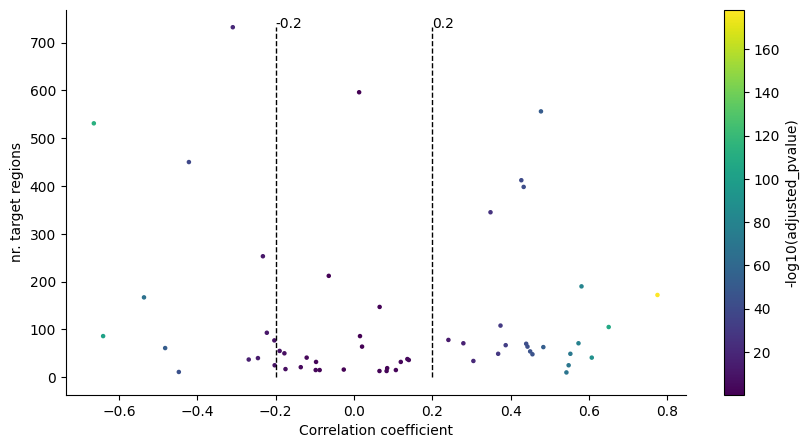

In [22]:
import numpy as np
n_targets = [int(x.split('(')[1].replace('r)', '')) for x in scplus_obj.uns['TF_cistrome_correlation']['filtered_region_based']['Cistrome']]
rho = scplus_obj.uns['TF_cistrome_correlation']['filtered_region_based']['Rho'].to_list()
adj_pval = scplus_obj.uns['TF_cistrome_correlation']['filtered_region_based']['Adjusted_p-value'].to_list()

thresholds = {
        'rho': [-0.2, 0.2],
        'n_targets': 0
}
import seaborn as sns
fig, ax = plt.subplots(figsize = (10, 5))
sc = ax.scatter(rho, n_targets, c = -np.log10(adj_pval), s = 5)
ax.set_xlabel('Correlation coefficient')
ax.set_ylabel('nr. target regions')
#ax.hlines(y = thresholds['n_targets'], xmin = min(rho), xmax = max(rho), color = 'black', ls = 'dashed', lw = 1)
ax.vlines(x = thresholds['rho'], ymin = 0, ymax = max(n_targets), color = 'black', ls = 'dashed', lw = 1)
ax.text(x = thresholds['rho'][0], y = max(n_targets), s = str(thresholds['rho'][0]))
ax.text(x = thresholds['rho'][1], y = max(n_targets), s = str(thresholds['rho'][1]))
sns.despine(ax = ax)
fig.colorbar(sc, label = '-log10(adjusted_pvalue)', ax = ax)
plt.show()

In [23]:
## Filtering cistromes for plotting - based on correlation
selected_cistromes = scplus_obj.uns['TF_cistrome_correlation']['filtered_region_based'].loc[
        np.logical_or(
                scplus_obj.uns['TF_cistrome_correlation']['filtered_region_based']['Rho'] > thresholds['rho'][1],
                scplus_obj.uns['TF_cistrome_correlation']['filtered_region_based']['Rho'] < thresholds['rho'][0]
        )]['Cistrome'].to_list()

## Additionally filtering based on a minimum number of target regions/genes
selected_cistromes = pd.Series(selected_cistromes)
# large_cistromes = scplus_obj.uns['eRegulon_metadata']['Region_signature_name'][(scplus_obj.uns['eRegulon_metadata']['Region_counts']>=100) & (scplus_obj.uns['eRegulon_metadata']['Gene_counts']>=50)].unique()
large_cistromes = scplus_obj.uns['eRegulon_metadata']['Region_signature_name'][(scplus_obj.uns['eRegulon_metadata']['Region_counts']>=50) & (scplus_obj.uns['eRegulon_metadata']['Gene_counts']>=25)].unique()
selected_cistromes = selected_cistromes[selected_cistromes.isin(large_cistromes)].tolist()
selected_eRegulons = [x.split('_(')[0] for x in selected_cistromes]
selected_eRegulons_gene_sig = [
        x for x in scplus_obj.uns['eRegulon_signatures']['Gene_based'].keys()
        if x.split('_(')[0] in selected_eRegulons]
selected_eRegulons_region_sig = [
        x for x in scplus_obj.uns['eRegulon_signatures']['Region_based'].keys()
        if x.split('_(')[0] in selected_eRegulons]
#save the results in the scenicplus object
scplus_obj.uns['selected_eRegulon'] = {'Gene_based': selected_eRegulons_gene_sig, 'Region_based': selected_eRegulons_region_sig}
print(f'selected: {len(selected_eRegulons_gene_sig)} eRegulons')

selected: 25 eRegulons


In [24]:
from scenicplus.plotting.dotplot import heatmap_dotplot
heatmap_dotplot(
        scplus_obj = scplus_obj,
        size_matrix = scplus_obj.uns['eRegulon_AUC_filtered']['Region_based'], #specify what to plot as dot sizes, target region enrichment in this case
        color_matrix = scplus_obj.to_df('EXP'), #specify  what to plot as colors, TF expression in this case
        scale_size_matrix = True,
        scale_color_matrix = True,
        group_variable = grouping_variable,
        subset_eRegulons = scplus_obj.uns['selected_eRegulon']['Gene_based'],
        figsize = (25,25),
        save = (work_dir + 'scenicplus_full/scplus_dotplot.png'),
        orientation = 'vertical')

2026-05-13 13:02:02,184 matplotlib.font_manager INFO     Fontsize 0.00 < 1.0 pt not allowed by FreeType. Setting fontsize = 1 pt


In [25]:
## Subset for activators only
activators = []
for reg in scplus_obj.uns['selected_eRegulon']['Region_based']:
    if '+_+' in reg:
        activators.append(reg)

scplus_obj.uns['eRegulon_AUC_filtered_activators'] = {}
scplus_obj.uns['eRegulon_AUC_filtered_activators']['Region_based'] = scplus_obj.uns['eRegulon_AUC_filtered']['Region_based'].loc[:,activators]

heatmap_dotplot(
        scplus_obj = scplus_obj,
        size_matrix = scplus_obj.uns['eRegulon_AUC_filtered_activators']['Region_based'], #specify what to plot as dot sizes, target region enrichment in this case
        color_matrix = scplus_obj.to_df('EXP'), #specify  what to plot as colors, TF expression in this case
        scale_size_matrix = True,
        scale_color_matrix = True,
        group_variable = grouping_variable,
        subset_eRegulons = activators,
        split_repressor_activator=False,
        figsize = (25,25),
        save = (work_dir + 'scenicplus_full/scplus_dotplot_activators.png'),
        orientation = 'vertical')

2026-05-13 13:02:03,443 matplotlib.font_manager INFO     Fontsize 0.00 < 1.0 pt not allowed by FreeType. Setting fontsize = 1 pt


In [26]:
## Subset for repressors only
repressors = []
for reg in scplus_obj.uns['selected_eRegulon']['Region_based']:
    if '-_+' in reg:
        repressors.append(reg)

scplus_obj.uns['eRegulon_AUC_filtered_repressors'] = {}
scplus_obj.uns['eRegulon_AUC_filtered_repressors']['Region_based'] = scplus_obj.uns['eRegulon_AUC_filtered']['Region_based'].loc[:,repressors]

heatmap_dotplot(
        scplus_obj = scplus_obj,
        size_matrix = scplus_obj.uns['eRegulon_AUC_filtered_repressors']['Region_based'], #specify what to plot as dot sizes, target region enrichment in this case
        color_matrix = scplus_obj.to_df('EXP'), #specify  what to plot as colors, TF expression in this case
        scale_size_matrix = True,
        scale_color_matrix = True,
        group_variable = grouping_variable,
        subset_eRegulons = repressors,
        split_repressor_activator=False,
        figsize = (25,25),
        save = (work_dir + 'scenicplus_full/scplus_dotplot_repressors.png'),
        orientation = 'vertical')

2026-05-13 13:02:04,397 matplotlib.font_manager INFO     Fontsize 0.00 < 1.0 pt not allowed by FreeType. Setting fontsize = 1 pt


In [27]:
from scenicplus.RSS import *
regulon_specificity_scores(
        scplus_obj,
        variable = grouping_variable,
        auc_key = 'eRegulon_AUC_filtered',
        signature_keys = ['Region_based'],
        selected_regulons = [x for x in scplus_obj.uns['selected_eRegulon']['Region_based'] if '-' not in x],
        out_key_suffix = '_filtered')

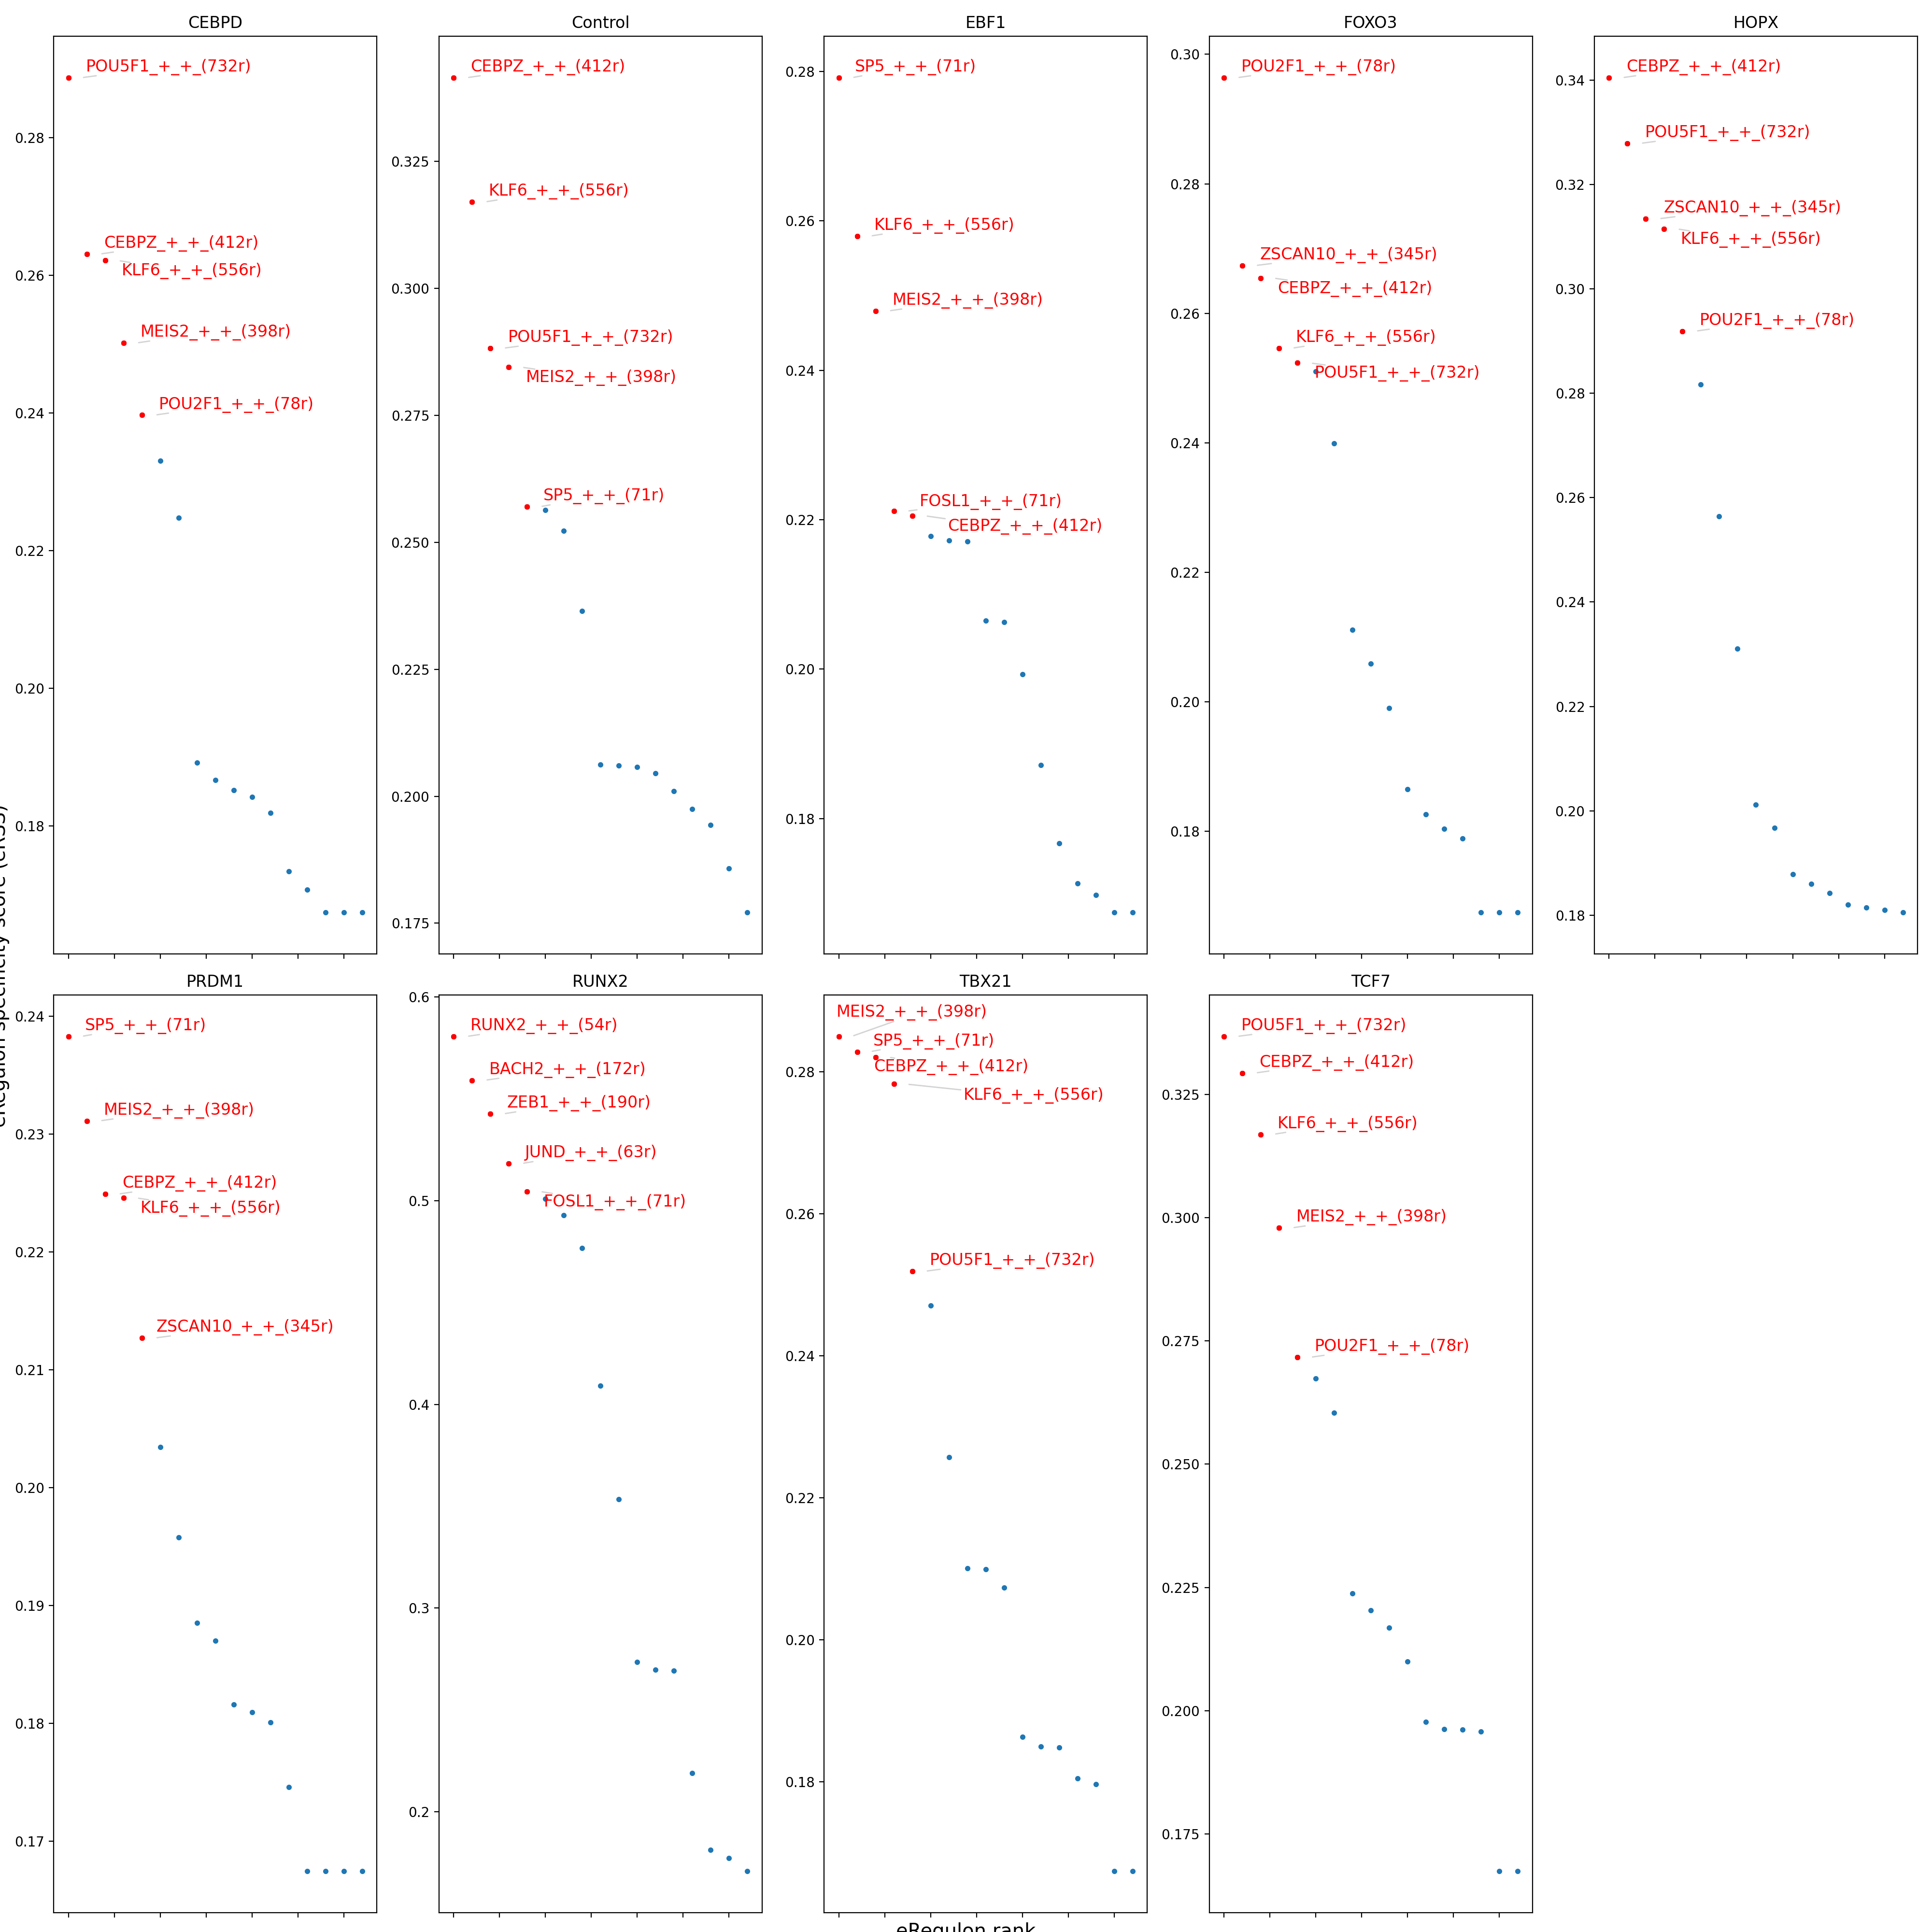

In [28]:
plot_rss(scplus_obj, (grouping_variable + '_filtered'), num_columns=5, top_n=5, figsize = (20, 20))

In [29]:
## Export scenicplus object
with open((work_dir + "scenicplus_full/scplus_obj_with_regulons.pkl"), "wb") as f:
    dill.dump(scplus_obj, f)

In [30]:
grn_comb_high_conf[grn_comb_high_conf.TF=='EOMES'][1:60]

,Triplet,TF,Region,Gene,TF2G_sign,R2G_sign,TF2R,R2G,TF2G,n_called_triplet_full,n_called_R2G_full,n_called_TF2G_full,n_called_TF2R_full,n_called_tf_full,Region_counts,Gene_counts,Region_signature_name,Gene_signature_name
EOMES#chr10:93702261-93702761#LGI1,EOMES#chr10:93702261-93702761#LGI1,EOMES,chr10:93702261-93702761,LGI1,+,+,EOMES#chr10:93702261-93702761,chr10:93702261-93702761#LGI1,EOMES#LGI1,5,9,5,5,12,48,42,EOMES_+_+_(48r),EOMES_+_+_(42g)
EOMES#chr11:236162-236662#IFITM3,EOMES#chr11:236162-236662#IFITM3,EOMES,chr11:236162-236662,IFITM3,+,+,EOMES#chr11:236162-236662,chr11:236162-236662#IFITM3,EOMES#IFITM3,7,10,7,7,12,48,42,EOMES_+_+_(48r),EOMES_+_+_(42g)
EOMES#chr11:447899-448399#IFITM3,EOMES#chr11:447899-448399#IFITM3,EOMES,chr11:447899-448399,IFITM3,+,+,EOMES#chr11:447899-448399,chr11:447899-448399#IFITM3,EOMES#IFITM3,5,7,7,5,12,48,42,EOMES_+_+_(48r),EOMES_+_+_(42g)
EOMES#chr11:57213217-57213717#APLNR,EOMES#chr11:57213217-57213717#APLNR,EOMES,chr11:57213217-57213717,APLNR,+,+,EOMES#chr11:57213217-57213717,chr11:57213217-57213717#APLNR,EOMES#APLNR,7,9,7,7,12,48,42,EOMES_+_+_(48r),EOMES_+_+_(42g)
EOMES#chr11:57335681-57336181#APLNR,EOMES#chr11:57335681-57336181#APLNR,EOMES,chr11:57335681-57336181,APLNR,+,+,EOMES#chr11:57335681-57336181,chr11:57335681-57336181#APLNR,EOMES#APLNR,6,11,7,6,12,48,42,EOMES_+_+_(48r),EOMES_+_+_(42g)
EOMES#chr11:6611983-6612483#DNHD1,EOMES#chr11:6611983-6612483#DNHD1,EOMES,chr11:6611983-6612483,DNHD1,+,+,EOMES#chr11:6611983-6612483,chr11:6611983-6612483#DNHD1,EOMES#DNHD1,5,5,5,5,12,48,42,EOMES_+_+_(48r),EOMES_+_+_(42g)
EOMES#chr11:69638963-69639463#FGF4,EOMES#chr11:69638963-69639463#FGF4,EOMES,chr11:69638963-69639463,FGF4,+,+,EOMES#chr11:69638963-69639463,chr11:69638963-69639463#FGF4,EOMES#FGF4,6,7,6,6,12,48,42,EOMES_+_+_(48r),EOMES_+_+_(42g)
EOMES#chr12:132083895-132084395#GALNT9,EOMES#chr12:132083895-132084395#GALNT9,EOMES,chr12:132083895-132084395,GALNT9,-,+,EOMES#chr12:132083895-132084395,chr12:132083895-132084395#GALNT9,EOMES#GALNT9,5,6,6,5,12,16,13,EOMES_-_+_(16r),EOMES_-_+_(13g)
EOMES#chr12:132084797-132085297#GALNT9,EOMES#chr12:132084797-132085297#GALNT9,EOMES,chr12:132084797-132085297,GALNT9,-,+,EOMES#chr12:132084797-132085297,chr12:132084797-132085297#GALNT9,EOMES#GALNT9,6,6,6,6,12,16,13,EOMES_-_+_(16r),EOMES_-_+_(13g)
EOMES#chr12:23949676-23950176#SOX5,EOMES#chr12:23949676-23950176#SOX5,EOMES,chr12:23949676-23950176,SOX5,+,+,EOMES#chr12:23949676-23950176,chr12:23949676-23950176#SOX5,EOMES#SOX5,5,5,5,5,12,48,42,EOMES_+_+_(48r),EOMES_+_+_(42g)


In [31]:
scplus_obj.uns['eRegulon_AUC_filtered']['Region_based']

,ARID3A_+_+_(15r),BACH2_+_+_(172r),BCL11A_-_+_(15r),BPTF_-_+_(61r),CEBPZ_+_+_(412r),CEBPZ_-_+_(86r),DRAP1_+_+_(596r),E2F1_-_+_(19r),E2F7_+_+_(38r),EGR1_-_+_(37r),...,TEAD1_+_+_(105r),THRB_+_+_(49r),THRB_-_+_(37r),ZBTB14_-_+_(17r),ZBTB16_+_+_(34r),ZBTB16_-_+_(40r),ZEB1_+_+_(190r),ZNF518A_-_+_(64r),ZSCAN10_+_+_(345r),ZSCAN10_-_+_(531r)
Cell,,,,,,,,,,,,,,,,,,,,,
CEBPD-SEACell-0,0.000000,0.0,0.0,0.0,0.012574,0.009722,0.013945,0.0,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.005635,0.000000,0.001760
CEBPD-SEACell-1,0.000000,0.0,0.0,0.0,0.006128,0.000000,0.006840,0.0,0.0,0.021415,...,0.000000,0.0,0.0,0.0,0.009322,0.010929,0.000000,0.002135,0.003500,0.002089
CEBPD-SEACell-10,0.000000,0.0,0.0,0.0,0.001419,0.009595,0.002310,0.0,0.0,0.002511,...,0.002602,0.0,0.0,0.0,0.007393,0.021175,0.004055,0.004525,0.005354,0.006195
CEBPD-SEACell-11,0.000000,0.0,0.0,0.0,0.020346,0.003940,0.019502,0.0,0.0,0.011815,...,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.004415
CEBPD-SEACell-12,0.000000,0.0,0.0,0.0,0.005120,0.000000,0.004117,0.0,0.0,0.012258,...,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.004071,0.005485
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCF7-SEACell-47,0.054281,0.0,0.0,0.0,0.005319,0.000000,0.005785,0.0,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.004752,0.000000
TCF7-SEACell-48,0.000000,0.0,0.0,0.0,0.010199,0.004130,0.010324,0.0,0.0,0.023187,...,0.000000,0.0,0.0,0.0,0.025072,0.010929,0.000000,0.002391,0.003073,0.004909
TCF7-SEACell-5,0.000000,0.0,0.0,0.0,0.015823,0.006227,0.011736,0.0,0.0,0.013144,...,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.010579


In [32]:
selected_cistromes

['BACH2_+_+_(172r)',
 'BPTF_-_+_(61r)',
 'CEBPZ_+_+_(412r)',
 'CEBPZ_-_+_(86r)',
 'FOSL1_+_+_(71r)',
 'HMGA1_-_+_(167r)',
 'JUND_+_+_(63r)',
 'KLF6_+_+_(556r)',
 'KLF6_-_+_(77r)',
 'KLF7_-_+_(253r)',
 'MBNL2_+_+_(70r)',
 'MEF2A_+_+_(67r)',
 'MEF2A_-_+_(93r)',
 'MEIS2_+_+_(398r)',
 'MEIS2_-_+_(450r)',
 'NFE2L2_+_+_(108r)',
 'POU2F1_+_+_(78r)',
 'POU5F1_+_+_(732r)',
 'RUNX2_+_+_(54r)',
 'SMAD3_+_+_(64r)',
 'SP5_+_+_(71r)',
 'TEAD1_+_+_(105r)',
 'ZEB1_+_+_(190r)',
 'ZSCAN10_+_+_(345r)',
 'ZSCAN10_-_+_(531r)']

In [33]:
scplus_obj.uns['TF_cistrome_correlation']['filtered_region_based'][scplus_obj.uns['TF_cistrome_correlation']['filtered_region_based']['TF']=='FOXO3']

,TF,Cistrome,Rho,P-value,Adjusted_p-value


In [34]:
scplus_obj.uns['TF_cistrome_correlation']['filtered_region_based']['TF'].unique()

array(['ARID3A', 'BACH2', 'BCL11A', 'BPTF', 'CEBPZ', 'DRAP1', 'E2F1',
       'E2F7', 'EGR1', 'ELK4', 'EOMES', 'FOSL1', 'FOSL2', 'FOXH1',
       'FOXO1', 'HMGA1', 'HOXB2', 'JUND', 'KLF12', 'KLF16', 'KLF3',
       'KLF5', 'KLF6', 'KLF7', 'MBNL2', 'MEF2A', 'MEIS2', 'NFE2L2',
       'NFXL1', 'NFYB', 'NR3C1', 'PLAGL1', 'POU2F1', 'POU5F1', 'RFX3',
       'RUNX2', 'SMAD3', 'SOX11', 'SOX4', 'SP5', 'TEAD1', 'THRB',
       'ZBTB14', 'ZBTB16', 'ZEB1', 'ZNF518A', 'ZSCAN10'], dtype=object)

In [35]:
scplus_obj.uns['TF_cistrome_correlation']['filtered_gene_based']['TF'].unique()

array(['BACH2', 'BCL11A', 'BPTF', 'CEBPZ', 'DRAP1', 'ELK4', 'EOMES',
       'FOSL1', 'FOXH1', 'FOXO1', 'HMGA1', 'HOXB2', 'JUND', 'KLF12',
       'KLF5', 'KLF6', 'KLF7', 'MBNL2', 'MEF2A', 'MEIS2', 'NFE2L2',
       'POU2F1', 'POU5F1', 'RUNX2', 'SMAD3', 'SOX11', 'SOX2', 'SOX4',
       'SP5', 'TEAD1', 'THRB', 'ZBTB16', 'ZEB1', 'ZSCAN10'], dtype=object)

In [36]:
scplus_obj.uns["Pseudobulk"]

{'GEX_perturbation': {'Expression':               TCF7_0    TCF7_1    TCF7_2    TCF7_3    TCF7_4    TCF7_5  \
  AL627309.1  0.802214  0.000000  0.000000  1.602400  0.000000  0.000000   
  AL627309.5  1.603144  1.601365  1.819100  1.817691  1.819709  2.403983   
  LINC01409   2.553359  2.841362  2.750793  2.750005  3.404476  3.180779   
  LINC01128   2.405358  2.748151  2.405264  1.015527  1.602515  1.016359   
  AL645608.6  1.948692  1.601365  1.017529  0.799954  0.800544  0.000000   
  ...              ...       ...       ...       ...       ...       ...   
  MT-ND5      6.520844  6.551138  6.545334  6.520766  6.535473  6.562954   
  MT-ND6      5.022552  4.916288  5.314526  5.255782  5.147828  5.235997   
  MT-CYB      6.896665  6.898618  6.903292  6.850446  6.868046  6.894591   
  AC011043.1  3.282810  2.914123  3.059678  3.051402  3.181366  3.536309   
  AC240274.1  1.948692  0.801193  1.819100  0.802064  2.404579  1.016094   
  
                TCF7_6    TCF7_7    TCF7_8    TCF7_